# 2MA100 - Devoir Maison 2

**Sorbonne Université - 19 avril 2021**

Les exercices de ce devoir maison noté sur 20 points doivent être rendus au choix au format **Notebook** (`.ipynb`) ou **Script** (`.py`) en un ou plusieurs fichiers au plus tard le **7 mai 2021** à 20h00 sur [moodle](https://moodle-sciences.upmc.fr/moodle-2020/).

**Attention Plagiat !**

Les devoirs maisons doivent être codés et rendus de manière individuelle. A titre d'information,
voici une définition du plagiat adaptée du [Memento de l'Université de Genève](https://memento.unige.ch/doc/0008/) :

*Le plagiat consiste à insérer, dans un travail académique, des formulations, des
phrases, des passages, des morceaux de code, des images, de même que des idées ou
analyses repris de travaux d'autres auteurs, en les faisant passer pour siens.*

En particulier, le copier-coller à partir de sources trouvées sur Internet ou sur des travaux d'autres
étudiant·es sans citer les sources est considéré comme du plagiat et implique une note zéro.
Le plagiat constitue également une tentative de tricherie sanctionnée par
le règlement de l'université. La solution est d'indiquer dans vos devoirs tout de ce qui ne vient
pas de vous en mentionnant les sources (page Internet, livres, autre étudiant·e,...). Tous les
fichiers rendus seront analysés automatiquement avec un logiciel de détection des similarités
(entre étudiant·es et depuis Internet).

Les modules Numpy et Matplotlib peuvent être utiles dans certains exercices :

In [1]:
# A=[1,2,3,4]
# ((x,y) for x in A for y in B) # cartesian product
# l = sorted(list(((x,y,z,t) for x in A for y in A for z in A for t in A)))
# print(l)
# cont=0
# l1=list()
# for item in l:
#     s = set(item)
#     if len(s) == 4:
#         print(sorted(item))
#         l1.append(item)
# print(l1)

In [2]:
from itertools import combinations

def all_combos(s):
    n = len(s)
    for r in range(1, n+1):
        for combo in combinations(s, r):
            yield combo
list(all_combos([1,2,3,4]))
print(list(combinations([1,2,3,4],0)))

[()]


In [3]:
from itertools import chain, combinations
def powerset(iterable):
    "powerset([1,2,3]) --> () (1,) (2,) (3,) (1,2) (1,3) (2,3) (1,2,3)"
    s = list(iterable)
    return chain.from_iterable(combinations(s, r) for r in range(len(s)+1))

for result in powerset([1, 2, 3]):
    print(result)

()
(1,)
(2,)
(3,)
(1, 2)
(1, 3)
(2, 3)
(1, 2, 3)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Exercice 1: Conjecture due à Euler

Euler a conjecturé en 1769 qu'au moins $k$ puissances $k$-ième d'entiers strictement positifs sont nécessaires pour que la somme soit elle-même une puissance $k$-ième. En d'autres termes si $n \geq 2$, $k \geq 1$, $a_1,a_2,\dots,a_n \geq 1$, et $b \geq 1$ sont des entiers tels que

$$
\sum_{i=1}^{n}(a_i)^k = b^k\,.
$$

alors nécessairement $n \geq k$.
Cette conjecture a été refutée en 1966 par Lander & Parkin ([doi:10.1090/S0002-9904-1966-11654-3](https://doi.org/10.1090/S0002-9904-1966-11654-3)) dans ce qui semble être le plus court article mathématique jamais écrit avec un contre-exemple pour $k=5$:

$$
27^5 + 84^5 + 110^5 + 133^5 = 144^5 \,.
$$

Le but est de montrer que ce contre-exemple est le plus simple possible, dans le sens où il est l'unique contre-exemple avec $k \leq 5$ et $b \leq 144$.

À noter que la conjecture est trivialement vraie pour $k=1$ et $k=2$ vu que par hypothèse $n \geq 2$, donc nécessairement $n \geq k$.

**a)**
Vérifier avec Python le contre-exemple ci-dessus.



In [5]:
27**5+84**5+110**5+133**5 == 144**5

True


**b)**
Écrire une fonction `powers(bmax,k)` qui retourne l'ensemble de tous les entiers de de 1 à `bmax` élevés à la puissance `k`.



In [6]:
def powers(bmax, k):
    return {x**k for x in range(1, bmax+1)}


**c)**
Vérifier qu'il n'existe pas de contre-exemple avec $k=3$ et $b \leq 144$.



In [7]:
ensemble = powers(144, 3)
for a1 in ensemble:
    for a2 in ensemble:        
        if a1 + a2 in ensemble:
            # si print(True) on a trouvé un contre-exemple
            print(True)


**d)**
Écrire une fonction `combinaisons(liste,n)` qui pour une liste d'entiers `liste` et un entier `n` retourne la liste de toutes les combinaisons avec répétitions de `n` entiers de `liste`
classés par ordre croissant. Par exemple `combinaisons([1,2,3,4],2)` doit retourner
`[(1,1), (1,2), (1,3), (1,4), (2,2), (2,3), (2,4), (3,3), (3,4), (4,4)]`.

**Indication:**
Utiliser une fonction récursive sur `n`.



In [8]:
def combin(n,k):
    """Nombre de combinaisons de n objets pris k a k (calcul récursif)"""
    if k==0 or k==n:
        return 1
    return combin(n-1, k-1) + combin(n-1,k)
combin(4 + 2 - 1, 2)

10

Une possible solution consiste à implémenter l'arbre des combinaisons de bas en haut et de gauche à droite. Par exemple pour liste=[1,2,3] et n=2
                                  n=0         1             2           3 ^
                                  n=1     1   2   3       2   3         3 | 
                                        ---------------------------->  

In [9]:
def combinaisons_liste(liste,n):
    if liste == []:
        return []
    if n==0:
        return [[]]
    else:
        crliste = combinaisons_liste(liste, n-1)
        for item in crliste:
            item.insert(0 ,liste[0])
        crliste += combinaisons_liste(liste[1:], n)
    return crliste

def combinaisons(liste, n):
    Lt=list()
    for c in combinaisons_liste(liste,n):
        Lt.append(tuple(c))
    return Lt

In [10]:
from itertools import combinations_with_replacement

liste = [1,2,3,4]
n = 3
# on vérifie avec le module itertools
list(combinations_with_replacement(liste,n)) == combinaisons(liste , n)

True


**e)**
Écrire une fonction `test(bmax,n,k)` qui pour trois entiers `bmax`, `n` et `k` donnés, itère sur toutes les combinaisons de `n` entiers retournés par `combinaisons` et vérifie si la somme de ces `n` entiers élevés à la puissance `k` est un entier présent dans la liste `powers(bmax,k)`. Utiliser cette fonction pour vérifier qu'il n'existe pas de contre-exemple à la conjecture d'Euler pour $k=4$ et $b \leq 144$. Suivant la puissance de votre ordinateur, il est possible de choisir également $k=5$ et donc de vérifier que le contre-exemple de l'introduction est bien le plus simple.



In [11]:
def test(bmax, n, k):
    ensemble = powers(bmax, k)
    for c in combinaisons(list(range(1, bmax + 1)), n):
        s = 0
        for v in c:
            s += v**k
        if s in ensemble:
            print(f'{c},{int(s**(1./k))}')
            break
# test(144, 2, 4) # pour deux entiers et k=4
# test(144, 3, 4) # pour trois entiers et k=4
# test(144, 2, 5) # pour deux entiers et k=5
# test(144, 3, 5) # pour trois entiers et k=5
# test(144, 4, 5) # pour quatre entiers et k=5


Pour $k=5$, la méthode précédente consistant à itérer sur toutes les combinaisons est plutôt lente. Une méthode plus rapide consiste à observer que l'ensemble des sommes du type:

$$
(a_1)^5 + (a_2)^5 + (a_3)^5 + (a_4)^5 \,,
$$

peut s'écrire comme $S_1 + S_2$ où $S_1$ et $S_2$ sont des sommes de deux entiers à la puissance cinq.

**f)**
Écrire une fonction `sum2(bmax,k)` qui retourne un dictionnaire ayant pour clefs les sommes $(a_1)^k+(a_2)^k$ avec la valeur associée $(a_1,a_2)$ pour $0 \leq a_1 \leq a_2 \leq$ `bmax`. On prendra soin d'enlever l'élément trivial zéro du dictionnaire. Dans la construction du dictionnaire, s'assurer qu'il est défini de manière unique dans le sens où il n'existe pas une autre valeur possible pour une clef existante. Tester `sum2(300,5)` et `sum2(300,3)`.



In [12]:
def sum2(bmax, k):
    somme = {}
    for a1 in range(1, bmax + 1):
        for a2 in range(a1, bmax + 1):
            somme[a1**5 + a2**5] = (a1, a2)
    return somme
# sum2(300,5)
# sum2(300,3)


**g)**
Utiliser le dictionnaire construit précédemment pour déterminer l'ensemble des contre-exemples pour $k=5$ et $b \leq 300$ en itérant sur tous les éléments de `power(bmax,5)` et de `sum2(bmax,5)`.

**Indication:**
Une implémentation optimale prend au plus quelques secondes à s'exécuter.



il y a 6 façons différentes d'obtenir des sommes partielles qui aboutiront au même résultat et sont redondantes
(27, 84, 110, 133), 61917364224
(27, 110, 84, 133), 61917364224
(27, 133, 84, 110), 61917364224
(84, 110, 27, 133), 61917364224
(84, 133, 27, 110), 61917364224
(110, 133, 27, 84), 61917364224
$C_4^2=6$

In [13]:
sommes = sum2(300, 5)
for p in powers(300, 5):
    for somme in sommes:
        if p <= somme: # ne traite pas les cas impossibles
            continue
        else:
            if p - somme in sommes: # la différence est dans la liste de puissances donc l'équation est satisfaite
                print(f'{sommes[somme] + sommes[p - somme]}, {int(p**(1./5))}')
                break # il y a 6 façons différentes d'obtenir des sommes partielles qui aboutiront au même résultat et sont redondantes

(27, 84, 110, 133), 144
(54, 168, 220, 266), 288


# Exercice 2: Ensemble de Mandelbrot

L'ensemble de Mandelbrot est défini comme l'ensemble des points $c\in\mathbb{C}$ pour lesquels la suite de nombres complexes définis récursivement par $z_0=0$ et

$$
z_{n+1} = z_n^2+c \,,
$$

est bornée.
Il est possible de montrer que $c\in\mathbb{C}$ est dans l'ensemble de Mandelbort si et seulement si $|z_n|\leq2$ pour tout entier $n$.

**a)**
Écrire une fonction `mandelbrot(c)` qui vérifie si le point $c\in\mathbb{C}$ est dans l'ensemble de Mandelbrot de manière approximative en testant les cent premiers termes.



In [14]:
def mandelbrot(c):
    """ Rend True ou False si c appartient à l'ensemble ou non, respectivement
    """
    z = 0j
    for _ in range(99):
        if abs(z) > 2.0:
            return False
        z = z**2 + c
    return True
print(mandelbrot(-0.1-0.641j))

True



**b)**
Tester la fonction précédente avec $c=0$ et $c=1+i$. Qu'est-il attendu théoriquement ?



La suite pour $c=1+i$, $\{0,1+i,1+3 i,-7+7 i,1-97 i,-9407-193 i\}$ n'est pas bornée, on attend False (n'appartient pas)
La suie constante $0$ appartient à l'ensemble (True)

In [15]:
print(mandelbrot(0j))
print(mandelbrot(1+1j))

True
False



**c)**
Écrire une fonction qui génère un tableau de taille $N\times N$ représentant l'ensemble $c \in \big\{x+iy: x\in[-2,2] \; \text{et} \; y\in[-2,2]\big\}$ et qui retourne un tableau de booléens de taille $N\times N$ déterminant si le point associé est dans l'ensemble de Mandelbrot ou non.



chap07, exercice 7.3

In [16]:
def tableau(N):
    lst = np.linspace(-2,2,N)
    x, y = np.meshgrid(lst,lst)
    c = x + 1j*y
    out = np.empty([N, N], dtype=bool)
    for i in range(N):
        for j in range(N):
            if mandelbrot(c[i,j]):
                out[i,j] = True
            else:
                out[i,j] = False
    return out


**d)**
En utilisant la fonction précédente avec $N=101$, représenter graphiquement avec `imshow` une approximation de l'ensemble des points appartenant à l'ensemble de Mandelbort.



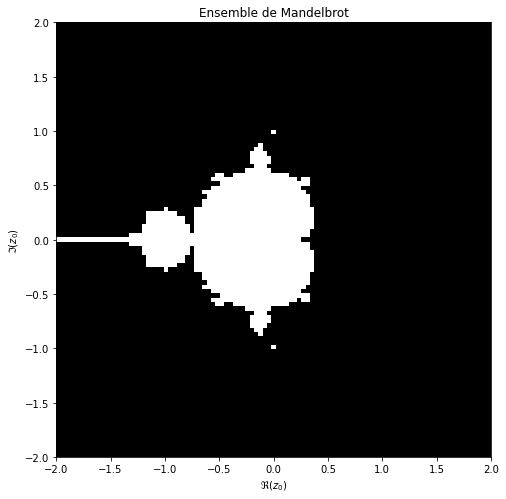

In [17]:
N=101
out = tableau(N)
graphe = np.zeros((N,N,3))
graphe[out == True] = [1,1,1] # RGB blanc
graphe[out == False] = [0,0,0] # RGB noir
plt.figure(figsize=(8, 8))
plt.title("Ensemble de Mandelbrot")
plt.xlabel(r"$\Re(z_0)$")
plt.ylabel(r"$\Im(z_0)$")
 # https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html
plt.imshow(graphe, extent=[-2,2,-2,2])
plt.show()


**e)**
En adaptant les fonctions précédentes, représenter graphiquement le logarithme du nombre d'itérations nécessaires avant de ne plus satisfaire $|z_n|\leq 2$ au lieu d'un booléean.



In [18]:
def mandelbrot1(c):
    z = 0j
    for k in range(99):
        if abs(z) > 2.0:
            return np.log10(k)
        z = z**2 + c
    return np.log10(100)
print(mandelbrot1(2-2j))

0.0


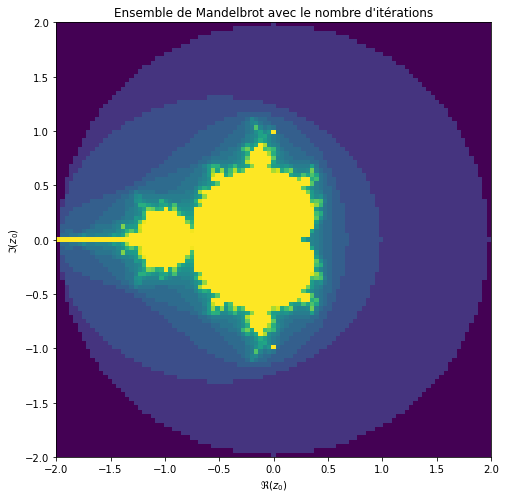

In [19]:
def tableau1(N):
    lst = np.linspace(-2,2,N)
    x, y = np.meshgrid(lst,lst)
    c = x + 1j*y
    out = np.empty((N, N), dtype=float)
    for i in range(N):
        for j in range(N):
            out[i,j] = mandelbrot1(c[i,j])
    return out
plt.figure(figsize=(8, 8))
plt.title("Ensemble de Mandelbrot avec le nombre d'itérations")
plt.xlabel(r"$\Re(z_0)$")
plt.ylabel(r"$\Im(z_0)$")
 # https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html
plt.imshow(tableau1(101), extent=[-2,2,-2,2])
plt.show()



<center>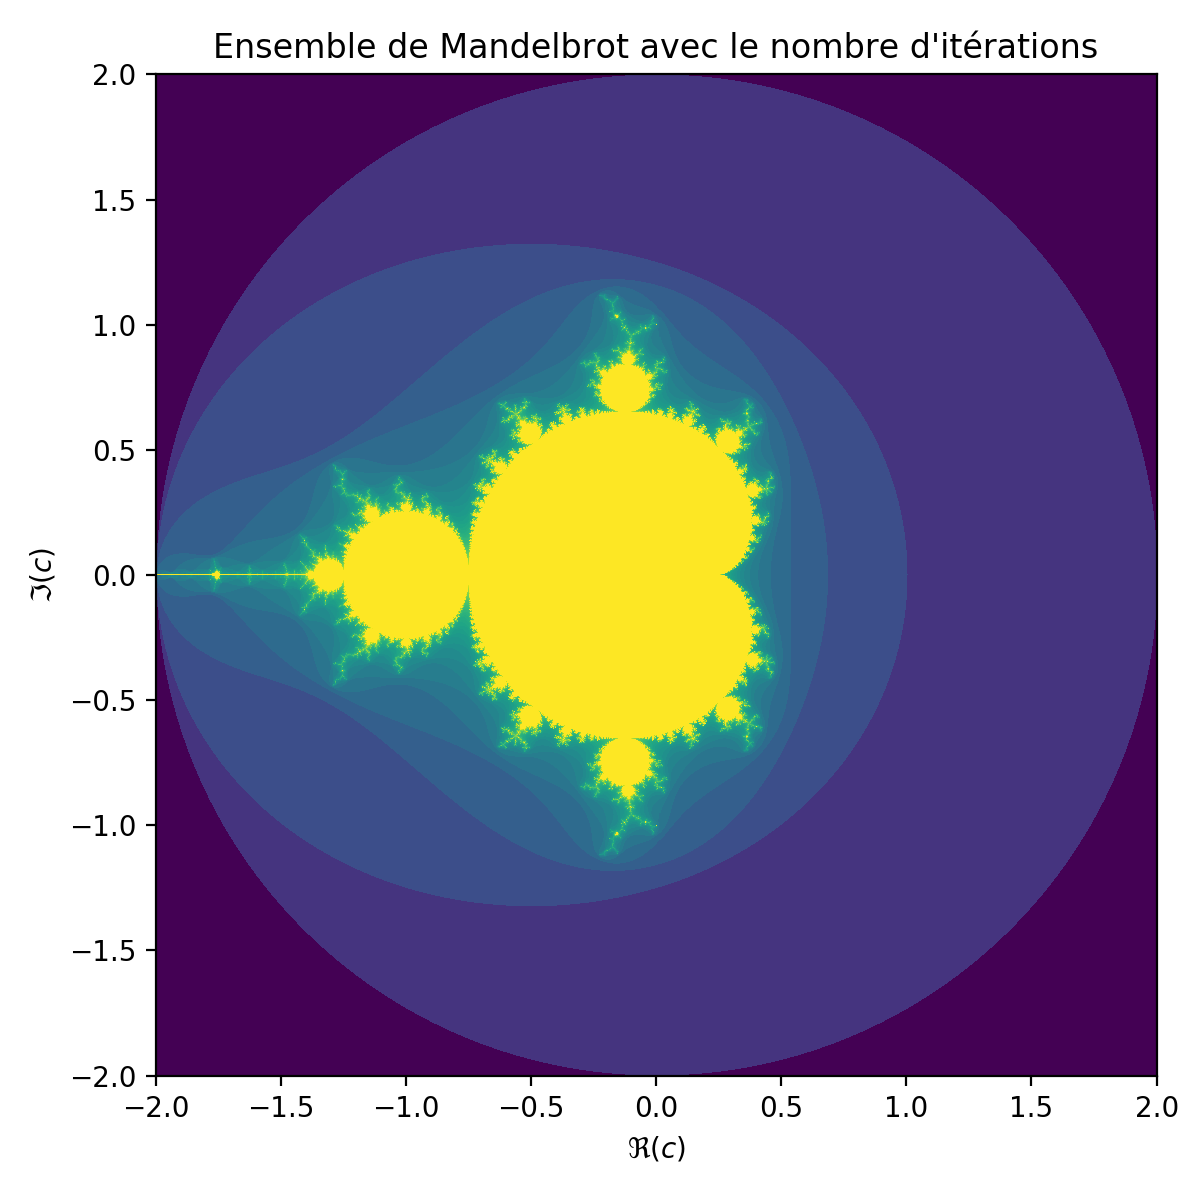</center>

**f)**
<span style="color:red">[bonus]</span> La méthode précédente a le désavantage de procéder séquentiellement au calcul pour chaque valeur de $c$, ce qui rend l'évaluation assez lente. Proposer une nouvelle implémentation permettant de calculer parallèlement toutes les valeurs en utilisant les indexages Numpy.



# Exercice 3: Théorème central limite

Le théorème central limite (aussi appelé théorème limite central, théorème de la limite centrale ou théorème de la limite centrée) établit la convergence en loi de la somme d'une suite de variables aléatoires vers la loi normale. Intuitivement, ce résultat affirme qu'une somme de variables aléatoires identiques et indépendantes tend (sous certaines conditions) vers une variable aléatoire gaussienne.

Voici une formulation de ce théorème :

>**Théorème.**
Soit $(X_n)$ une suite de variables aléatoires réelles indépendantes et de même loi admettant une espérance $\mu$ et un écart-type $\sigma \ne 0$.
Soit $(\bar{X}_n)$ la suites définie par $\displaystyle \bar{X}_n = \frac{1}{n} \sum_{k=1}^n X_k$.
Pour $n$ assez grand, la loi de $\bar{X}_n$ peut être approché par la loi normale $\mathcal{N}(\mu, \frac{\sigma^2}{n})$.

L'objectif de cet exercice est de vérifier si ce théorème est valable pour différentes lois de probabilité :

* **Loi de Poisson**: distribution discrète sur $\mathbb{N}$, de paramètre $\lambda$, définie par :

$$
\displaystyle \mathbb{P}(X = k) = \exp(-\lambda) \frac{\lambda^k}{k!}\,, \quad \forall k \in \mathbb{N} \,.
$$

* **Loi normale**: distribution continue sur $\mathbb{R}$, de paramètres $m$ et $\sigma$, définie par la densité :

$$
\displaystyle \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( - \frac{(x-m)^2}{2\sigma^2} \right)\,, \quad \forall x \in \mathbb{R} \,.
$$

* **Loi de Cauchy**: distribution continue sur $\mathbb{R}$, de paramètres $a$ et $\gamma$, définie par la densité :

$$
\displaystyle \frac{1}{\pi\gamma\left(1 + \left(\frac{x-a}{\gamma}\right)^2\right)}\,, \quad \forall x \in \mathbb{R} \,.
$$

**a)**
Définir une fonction `densite_loi_normale(x, mu var)` prenant comme un argument :
* `x` (tableau) : un tableau de nombres flottants

* `mu` (nombre flottant) : moyenne

* `var` (nombre flottant strictement positif) : variance $\sigma^2$

et qui renvoie la densité de la loi normale évaluée pour chaque nombre $x$ dans `x`:

$$
\mathcal{N}(\mu, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( - \frac{(x-\mu)^2}{2\sigma^2} \right) \,.
$$

In [92]:
def densite_loi_normale(x, mu, var):
    N = lambda x, mu, var: np.exp(-((x - mu)**2)/(2*var)) / np.sqrt(2*np.pi*var)
    N = np.vectorize(N)(x, mu,var)
    k = zip(x, N)
    return k

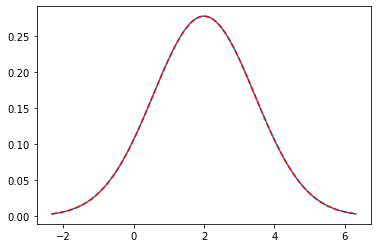

In [93]:
# On vérifie avec stats.norm.pdf()
import scipy.stats as stats

mu=2
sigma=1.44
s = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
plt.plot(s, stats.norm.pdf(s, 2, 1.44))
L =  densite_loi_normale(s, mu, sigma**2)
x, y = zip(*sorted(L))
plt.plot(s,y, color='r',linestyle='dashed')
plt.show()



**b)**
Regarder la documentation de la fonction [`numpy.random.poisson`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.poisson.html) et générer 10 valeurs aléatoires selon une loi de Poisson de paramètre $\lambda = 2$.



In [22]:
s = np.random.poisson(2, 10)
print(s)

[5 3 2 1 1 1 1 2 2 1]



**c)**
Écrire une fonction `generer_echantillons_poisson(lam, N, M)` qui prend en arguments :
* `lam` (réel strictement positif): paramètre $\lambda$ pour la loi de Poisson

* `N` (entier strictement positif): nombre d'expériences

* `M` (entier strictement positif): nombre de variables aléatoires générées pour chaque expérience

et qui génère `N` expériences avec `M` variables aléatoires générées par expérience, et qui renvoie :
* (nombre flottant) : la valeur moyenne sur les `N * M` variables aléatoires générées,

* (nombre flottant): l'écart-type sur les `N * M` variables aléatoires générées,

* (tableau) : vecteur numpy (*i.e.* un tableau de taille `(N,)`) où chaque élément est la moyenne des variables aléatoires d'une expérience.

Pour les valeurs `lam=2` et `N=10000`, exécuter `generer_echantillons_poisson(lam, N, M)` pour $M \in \{10, 100, 1000\}$ et sauvegarder les résultats dans des variables.



In [96]:
def generer_echantillons_poisson(lam, N, M):
    donnees = np.zeros((N,M))
    moyennes = np.zeros(N)
    for i in range(N):
        donnees[i] = np.random.poisson(lam, M)
        moyennes[i] = np.mean(donnees[i])
    return np.mean(donnees),np.std(donnees),moyennes

mu1, sigma1, moyennes1 = generer_echantillons_poisson(2, 10000, 10)
mu2, sigma2, moyennes2 = generer_echantillons_poisson(2, 10000, 100)
mu3, sigma3, moyennes3 = generer_echantillons_poisson(2, 10000, 1000)

##### **d)**
Pour chaque valeur de `M`, afficher la distribution du vecteur numpy contenant les moyennes de chaque expérience, ainsi que la distribution de la loi normale attendue si la théorème central limite est vérifié. On pourra utiliser la fonction [`matplotlib.pyplot.hist`](https://numpy.org/doc/stable/reference/generated/numpy.histogram.html) pour afficher l'histogramme d'un tableau, avec le paramètre `bins=50` pour fixer le nombre colonnes et `density=True` pour afficher une distribution de probabilité. On utilisera les moyennes et les écart-types empiriques renvoyés par la fonction `generer_echantillons_poisson` pour les paramètres de la loi normale.
Choisir des valeurs pertinentes pour les valeurs limites de l'axe des abscisses. Faire une hypothèse sur la validité du théorème central limite pour la loi de Poisson.



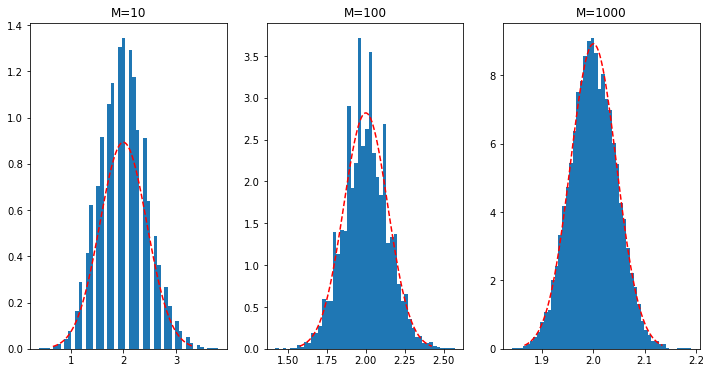

In [101]:
import math

plt.figure(figsize=(12,6))

mu = mu1
variance = sigma1**2/10
sigma = math.sqrt(variance)
x1 = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
plt.subplot(1,3,1)
L =  densite_loi_normale(x1, mu, variance)
x, y = zip(*sorted(L))
plt.plot(x,y, color='r',linestyle='dashed')
plt.hist(moyennes1,bins=50,density=True)
plt.title(f'M=10')

mu = mu2
variance = sigma2**2/100
sigma = math.sqrt(variance)
x2 = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
plt.subplot(1,3,2)
L =  densite_loi_normale(x2, mu, variance)
x, y = zip(*sorted(L))
plt.plot(x,y, color='r',linestyle='dashed')
plt.hist(moyennes2,bins=50,density=True)
plt.title(f'M=100')

mu = mu3
variance = sigma3**2/1000
sigma = math.sqrt(variance)
x3 = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
plt.subplot(1,3,3)
L =  densite_loi_normale(x3, mu, variance)
x, y = zip(*sorted(L))
plt.plot(x,y, color='r',linestyle='dashed')
plt.hist(moyennes3,bins=50,density=True)
plt.title(f'M=1000')

plt.show()

Le théorème central limite semble valide pour la loi de Poisson (pour les grands échantillons les histogrammes s'adaptent de mieux en mieux à la courbe de la loi normale théorique de moyenne $\mu$ et écart-type $\sigma^2/n$, ou $n=M$ et $\mu$ est la moyenne globale)


**e)**
Reprendre les questions **c)** et **d)** pour la loi normale. Pour cela utiliser la fonction [`numpy.random.normal`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html), générer des moyennes pour `loc=2`, `scale=1`, `N=10000` et $M \in \{10, 100, 1000\}$. Tracer les histogrammes et faire une hypothèse sur la validité du théorème central limite pour la loi normale.



In [102]:
def generer_echantillons_normale(loc, scale, N, M):
    donnees = np.zeros((N,M))
    moyennes = np.zeros(N)
    for i in range(N):
        donnees[i] = np.random.normal(loc, scale, M)
        moyennes[i] = np.mean(donnees[i])
    return np.mean(donnees),np.std(donnees),moyennes

mu1, sigma1, moyennes1 = generer_echantillons_normale(2, 1, 10000, 10)
mu2, sigma2, moyennes2 = generer_echantillons_normale(2, 1, 10000, 100)
mu3, sigma3, moyennes3 = generer_echantillons_normale(2, 1, 10000, 1000)

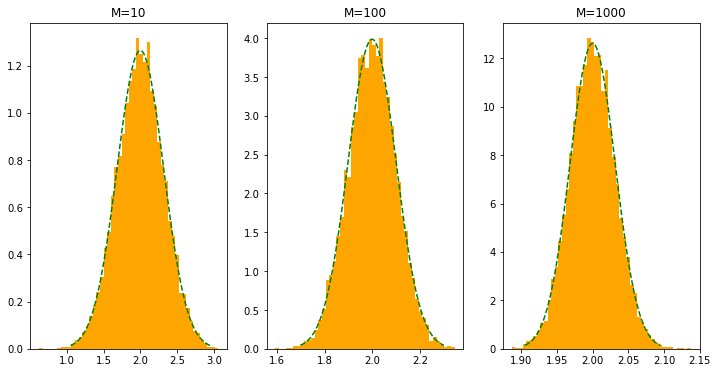

In [106]:
import math

plt.figure(figsize=(12,6))

mu = mu1
variance = sigma1**2/10
sigma = math.sqrt(variance)
x1 = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
plt.subplot(1,3,1)
L =  densite_loi_normale(x1, mu, variance)
x, y = zip(*sorted(L))
plt.plot(x,y, color='green',linestyle='dashed')
plt.hist(moyennes1,bins=50,density=True,color='orange')
plt.title(f'M=10')

mu = mu2
variance = sigma2**2/100
sigma = math.sqrt(variance)
x2 = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
plt.subplot(1,3,2)
L =  densite_loi_normale(x2, mu, variance)
x, y = zip(*sorted(L))
plt.plot(x,y, color='green',linestyle='dashed')
plt.hist(moyennes2,bins=50,density=True,color='orange')
plt.title(f'M=100')

mu = mu3
variance = sigma3**2/1000
sigma = math.sqrt(variance)
x3 = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
plt.subplot(1,3,3)
L =  densite_loi_normale(x3, mu, variance)
x, y = zip(*sorted(L))
plt.plot(x,y, color='green',linestyle='dashed')
plt.hist(moyennes3,bins=50,density=True,color='orange')
plt.title(f'M=1000')

plt.show()

Le théorème semble valide pour la loi normale


**f)**
Reprendre les questions **c)** et **d)** pour la loi de Cauchy avec $a=0$ et $\gamma=1$. Pour cela utiliser la fonction [`numpy.random.standard_cauchy`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.standard_cauchy.html). Utiliser `bins=np.arange(-10, 10.1, 0.1)` et faire une hypothèse sur la validité du théorème central limite pour la loi de Cauchy.



In [107]:
def generer_echantillons_cauchy(N, M):
    donnees = np.zeros((N,M))
    moyennes = np.zeros(N)
    for i in range(N):
        donnees[i] = np.random.standard_cauchy(M)
        moyennes[i] = np.mean(donnees[i])
    return np.mean(donnees),np.std(donnees),moyennes

mu1, sigma1, moyennes1 = generer_echantillons_cauchy(10000, 10)
mu2, sigma2, moyennes2 = generer_echantillons_cauchy(10000, 100)
mu3, sigma3, moyennes3 = generer_echantillons_cauchy(10000, 1000)

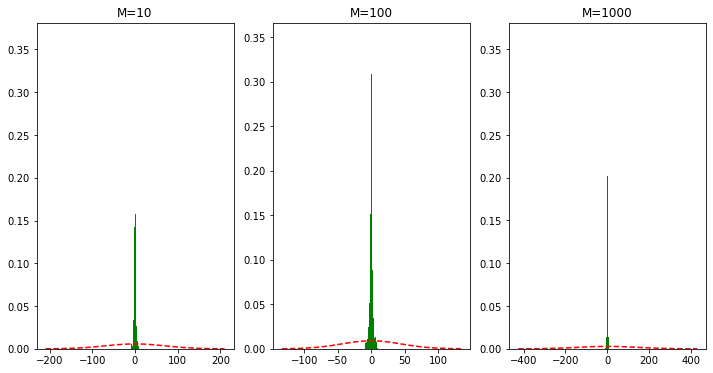

In [109]:
import math

plt.figure(figsize=(12,6))

cont = np.arange(-10, 10.1, 0.1)
mu = mu1
variance = sigma1**2/10
sigma = math.sqrt(variance)
x1 = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
plt.subplot(1,3,1)
L =  densite_loi_normale(x1, mu, variance)
x, y = zip(*sorted(L))
plt.plot(x,y, color='red',linestyle='dashed')
plt.hist(moyennes1,bins=cont,density=True,color='green')
plt.title(f'M=10')

mu = mu2
variance = sigma2**2/100
sigma = math.sqrt(variance)
x2 = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
plt.subplot(1,3,2)
L =  densite_loi_normale(x2, mu, variance)
x, y = zip(*sorted(L))
plt.plot(x,y, color='red',linestyle='dashed')
plt.hist(moyennes2,bins=cont,density=True,color='green')
plt.title(f'M=100')

mu = mu3
variance = sigma3**2/1000
sigma = math.sqrt(variance)
x3 = np.linspace(mu - 3*sigma, mu + 3*sigma, 100)
plt.subplot(1,3,3)
L =  densite_loi_normale(x3, mu, variance)
x, y = zip(*sorted(L))
plt.plot(x,y, color='red',linestyle='dashed')
plt.hist(moyennes3,bins=cont,density=True,color='green')
plt.title(f'M=1000')

plt.show()

0.03386312705550112 0.1536452945391792 1.854627447720362


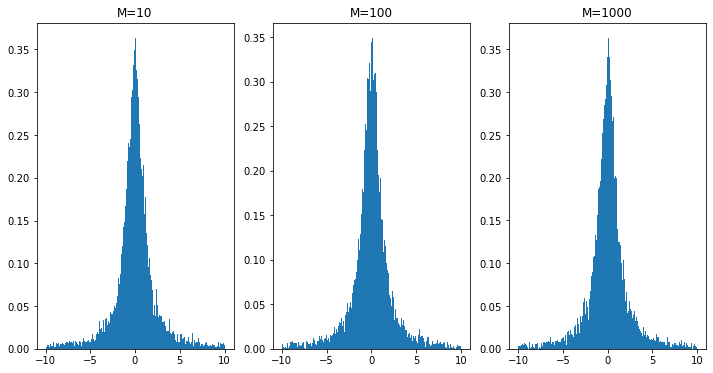

In [111]:
print(mu1,mu2,mu3)
plt.figure(figsize=(12,6))
cont = np.arange(-10, 10.1, 0.1)
plt.subplot(1,3,1)
plt.hist(moyennes1, bins=cont, density=True)
plt.title('M=10')
plt.subplot(1,3,2)
plt.hist(moyennes2, bins=cont, density=True)
plt.title('M=100')
plt.subplot(1,3,3)
plt.hist(moyennes3, bins=cont, density=True)
plt.title('M=1000')
plt.show()

Les trois histogrammes sont quasiment identiques, les moyennes sont cependant assez différentes. Le théorème ne semble pas valide pour la loi de Cauchy. Dans la figure ou se trouve l'histogramme et la courbe théorique, on ne voit pas bien clair le résultat mais c'est évident que la distribution de probabilité théorique est trés différente par rapport à celle obtenu de l'échantillon.